# 09 — Final Training and Export

This notebook trains and exports the **selected final models** for the project.

## Final HR model
**CNN + BiGRU PPG + IMU fusion**

Inputs:
- `PPG_Raw`
- `ACC_X`
- `ACC_Y`
- `ACC_Z`

Target:
- mean chest-strap HR within each exact 8-second window

## Final activity model
**IMU-only 1D CNN**

Inputs:
- `ACC_X`
- `ACC_Y`
- `ACC_Z`

Target:
- six activity classes

This notebook reuses the same exact 8-second preprocessing and chronological train / validation / test split used in the experimental notebooks.

Unlike the previous experiment notebooks, this notebook **does save the final models, normalization parameters, metrics and figures** into `results/`.


## 1. Imports and Project Paths

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight

PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
RESULTS_DIR = PROJECT_ROOT / "results"

MODELS_DIR = RESULTS_DIR / "models"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [MODELS_DIR, METRICS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from models import (
    build_cnn_bigru_hr_model,
    build_activity_cnn,
)

from preprocessing import (
    fit_channel_normalizer,
    apply_channel_normalizer,
)

from evaluation import (
    regression_metrics,
    regression_metrics_by_activity,
    classification_metrics,
    classification_report_dataframe,
    classification_confusion_matrix,
)

print("Project root :", PROJECT_ROOT)
print("Results dir  :", RESULTS_DIR)
print("TensorFlow   :", tf.__version__)

Project root : C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning
Results dir  : C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results
TensorFlow   : 2.21.0


## 2. Re-run Final Preprocessing

In [2]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Confirm Final Dataset

In [3]:
print("HR PPG-only shape :", X_ppg_train.shape)
print("Fusion shape      :", X_fusion_train.shape)
print("Train / Val / Test:", len(y_train), len(y_val), len(y_test))

assert X_fusion_train.shape[1:] == (320, 4)
assert X_ppg_train.shape[1:] == (320, 1)

print()
print("Activities:")
print(meta_train["Activity"].value_counts())

HR PPG-only shape : (1322, 320, 1)
Fusion shape      : (1322, 320, 4)
Train / Val / Test: 1322 281 292

Activities:
Activity
Sleep                 337
Walking               335
Low_Tempo_Cycling     255
Sitting               191
High_Tempo_Cycling    171
Eating                 33
Name: count, dtype: int64


## 4. Reproducibility

In [4]:
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Part A — Final Heart-Rate Regression Model

The final HR model is the **CNN + BiGRU PPG + IMU fusion architecture** selected from the regression experiments.


## 5. Prepare PPG and IMU Inputs

In [5]:
X_hr_ppg_train = X_fusion_train[:, :, 0:1]
X_hr_ppg_val   = X_fusion_val[:, :, 0:1]
X_hr_ppg_test  = X_fusion_test[:, :, 0:1]

X_hr_imu_train = X_fusion_train[:, :, 1:4]
X_hr_imu_val   = X_fusion_val[:, :, 1:4]
X_hr_imu_test  = X_fusion_test[:, :, 1:4]

print("PPG train:", X_hr_ppg_train.shape)
print("IMU train:", X_hr_imu_train.shape)

PPG train: (1322, 320, 1)
IMU train: (1322, 320, 3)


## 6. Fit Training-Only HR Normalization

In [6]:
ppg_mean, ppg_std = fit_channel_normalizer(
    X_hr_ppg_train
)

imu_mean, imu_std = fit_channel_normalizer(
    X_hr_imu_train
)

X_hr_ppg_train_norm = apply_channel_normalizer(
    X_hr_ppg_train, ppg_mean, ppg_std
)
X_hr_ppg_val_norm = apply_channel_normalizer(
    X_hr_ppg_val, ppg_mean, ppg_std
)
X_hr_ppg_test_norm = apply_channel_normalizer(
    X_hr_ppg_test, ppg_mean, ppg_std
)

X_hr_imu_train_norm = apply_channel_normalizer(
    X_hr_imu_train, imu_mean, imu_std
)
X_hr_imu_val_norm = apply_channel_normalizer(
    X_hr_imu_val, imu_mean, imu_std
)
X_hr_imu_test_norm = apply_channel_normalizer(
    X_hr_imu_test, imu_mean, imu_std
)

hr_norm_table = pd.DataFrame({
    "Channel": ["PPG_Raw", "ACC_X", "ACC_Y", "ACC_Z"],
    "Train_Mean": [
        float(ppg_mean.reshape(-1)[0]),
        *imu_mean.reshape(-1).tolist(),
    ],
    "Train_Std": [
        float(ppg_std.reshape(-1)[0]),
        *imu_std.reshape(-1).tolist(),
    ],
})

display(hr_norm_table.round(5))

,Channel,Train_Mean,Train_Std
0,PPG_Raw,4475.98584,1247.35583
1,ACC_X,-0.32539,0.55772
2,ACC_Y,0.34338,0.23384
3,ACC_Z,-0.67551,0.31986


## 7. Build Final HR Model

In [7]:
hr_model = build_cnn_bigru_hr_model(
    input_length=320
)

hr_model.summary()

Model: "CNN_BiGRU_PPG_IMU_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ppg_input           │ (None, 320, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imu_input           │ (None, 320, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 320, 32)   │        256 │ ppg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 320, 32)   │        704 │ imu_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 320, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 320, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ppg_bigru           │ (None, 96)        │     32,832 │ max_pooling1d_1[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imu_bigru           │ (None, 96)        │     32,832 │ max_pooling1d_3[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,208 │ ppg_bigru[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,208 │ imu_bigru[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 128)       │          0 │ dense[0][0],    

 Total params: 108,737 (424.75 KB)

 Trainable params: 108,353 (423.25 KB)

 Non-trainable params: 384 (1.50 KB)

## 8. Train Final HR Model

In [ ]:
hr_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1,
    ),
]

hr_history = hr_model.fit(
    [
        X_hr_ppg_train_norm,
        X_hr_imu_train_norm,
    ],
    y_train,
    validation_data=(
        [
            X_hr_ppg_val_norm,
            X_hr_imu_val_norm,
        ],
        y_val
    ),
    epochs=180,
    batch_size=32,
    callbacks=hr_callbacks,
    verbose=1,
)

## 9. Evaluate Final HR Model

In [9]:
y_pred_hr = hr_model.predict(
    [
        X_hr_ppg_test_norm,
        X_hr_imu_test_norm,
    ],
    verbose=0
).reshape(-1)

hr_overall = regression_metrics(
    y_test,
    y_pred_hr
)

hr_metrics_df = pd.DataFrame([{
    "Model": "CNN + BiGRU PPG + IMU",
    **hr_overall,
}])

display(hr_metrics_df.round(4))

hr_per_activity_df = regression_metrics_by_activity(
    y_true=y_test,
    y_pred=y_pred_hr,
    activities=meta_test["Activity"].to_numpy(),
    activity_order=ACTIVITY_ORDER,
)

display(hr_per_activity_df.round(4))

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,CNN + BiGRU PPG + IMU,3.8647,6.2433,0.9304,0.9659,89.1626,23.6625,88.3685,23.745


,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,5.2282,5.8250,-0.4026,0.4653,84.9150,4.9184,81.0497,2.0941
1,High_Tempo_Cycling,38,8.6333,10.7774,-0.2000,-0.1780,113.8829,9.8385,113.7874,2.9830
2,Low_Tempo_Cycling,56,4.3503,5.1984,-0.8527,-0.2146,112.1263,3.8192,110.8693,2.5758
3,Sitting,43,3.9566,6.4668,0.1655,0.7038,72.8948,7.0791,72.8614,9.0475
4,Sleep,73,1.4553,1.7938,-1.0361,0.3811,56.0559,1.2571,54.8083,1.0363
5,Walking,74,3.2243,6.5246,-3.5878,-0.0907,101.6620,3.0461,101.1969,5.4813


## 10. Save Final HR Model and Normalization

In [10]:
hr_model_path = MODELS_DIR / "hr_cnn_bigru.keras"
hr_norm_path = MODELS_DIR / "hr_normalization.npz"

hr_model.save(hr_model_path)

np.savez(
    hr_norm_path,
    ppg_mean=ppg_mean,
    ppg_std=ppg_std,
    imu_mean=imu_mean,
    imu_std=imu_std,
)

print("Saved:", hr_model_path)
print("Saved:", hr_norm_path)

Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\models\hr_cnn_bigru.keras
Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\models\hr_normalization.npz


## 11. Save HR Metrics

In [11]:
hr_metrics_path = METRICS_DIR / "hr_metrics.csv"
hr_per_activity_path = METRICS_DIR / "hr_per_activity_metrics.csv"

hr_metrics_df.to_csv(
    hr_metrics_path,
    index=False
)

hr_per_activity_df.to_csv(
    hr_per_activity_path,
    index=False
)

print("Saved:", hr_metrics_path)
print("Saved:", hr_per_activity_path)

Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\hr_metrics.csv
Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\hr_per_activity_metrics.csv


## 12. Save HR Figures

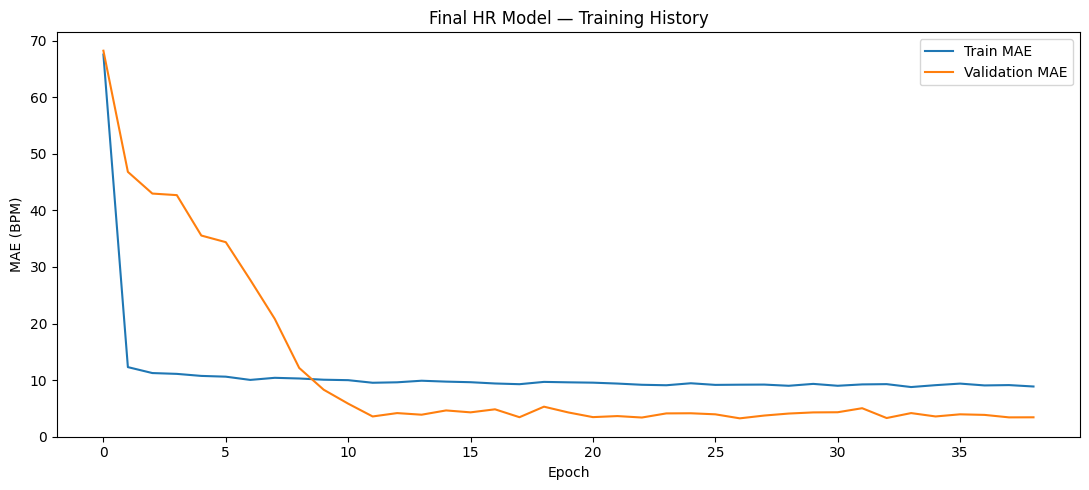

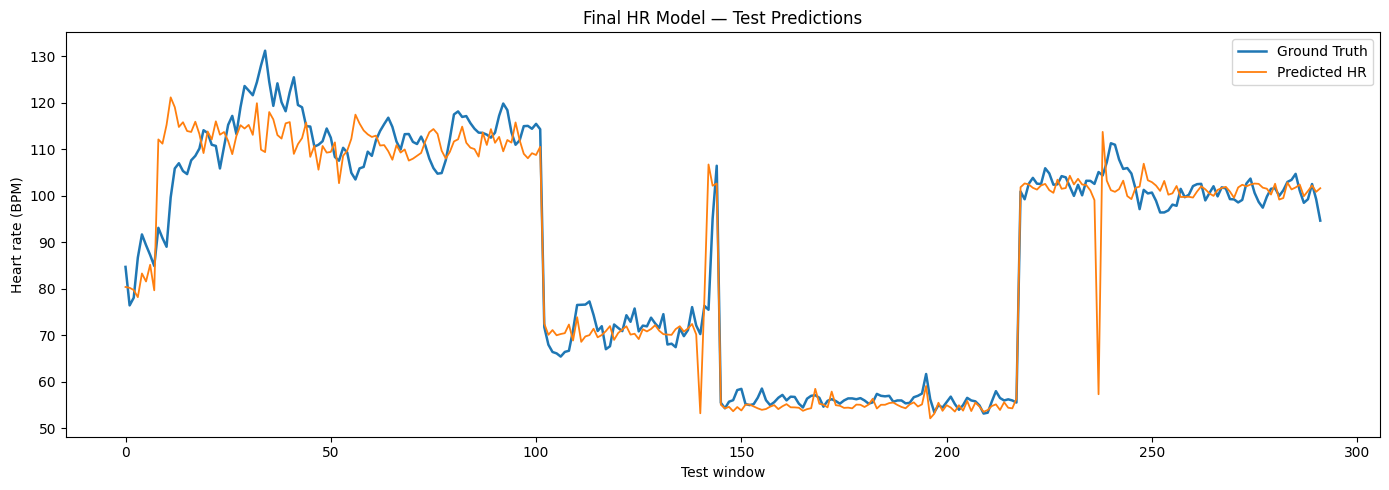

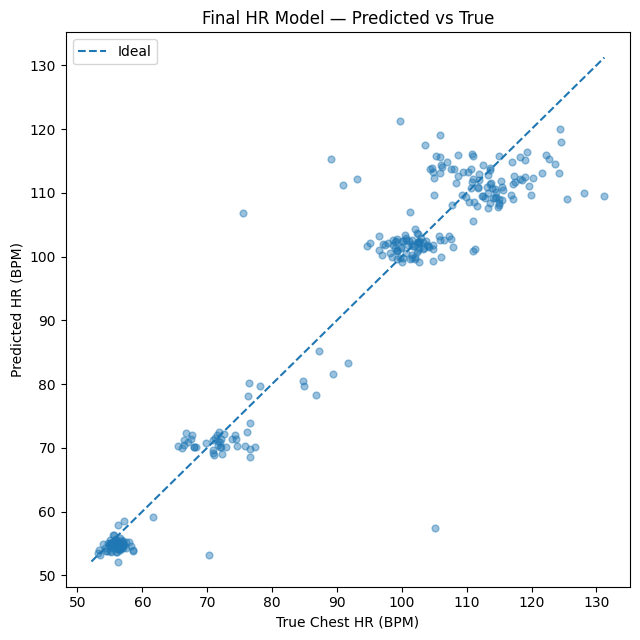

Saved HR figures.


In [12]:
hr_history_df = pd.DataFrame(
    hr_history.history
)

plt.figure(figsize=(11, 5))
plt.plot(
    hr_history_df["mae"],
    label="Train MAE"
)
plt.plot(
    hr_history_df["val_mae"],
    label="Validation MAE"
)
plt.xlabel("Epoch")
plt.ylabel("MAE (BPM)")
plt.title("Final HR Model — Training History")
plt.legend()
plt.tight_layout()

hr_history_path = FIGURES_DIR / "hr_training_history.png"
plt.savefig(
    hr_history_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(14, 5))
plt.plot(
    y_test,
    label="Ground Truth",
    linewidth=1.8
)
plt.plot(
    y_pred_hr,
    label="Predicted HR",
    linewidth=1.3
)
plt.xlabel("Test window")
plt.ylabel("Heart rate (BPM)")
plt.title("Final HR Model — Test Predictions")
plt.legend()
plt.tight_layout()

hr_predictions_path = FIGURES_DIR / "hr_test_predictions.png"
plt.savefig(
    hr_predictions_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()


low = float(min(y_test.min(), y_pred_hr.min()))
high = float(max(y_test.max(), y_pred_hr.max()))

plt.figure(figsize=(6.5, 6.5))
plt.scatter(
    y_test,
    y_pred_hr,
    s=24,
    alpha=0.45
)
plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)
plt.xlabel("True Chest HR (BPM)")
plt.ylabel("Predicted HR (BPM)")
plt.title("Final HR Model — Predicted vs True")
plt.legend()
plt.tight_layout()

hr_scatter_path = FIGURES_DIR / "hr_predicted_vs_true.png"
plt.savefig(
    hr_scatter_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved HR figures.")

# Part B — Final Activity Classification Model

The final activity classifier is the **IMU-only 1D CNN**, which outperformed the CNN + BiGRU classifier on balanced accuracy and Macro F1.


## 13. Prepare IMU Activity Inputs and Labels

In [13]:
X_activity_train = X_fusion_train[:, :, 1:4]
X_activity_val   = X_fusion_val[:, :, 1:4]
X_activity_test  = X_fusion_test[:, :, 1:4]

activity_to_id = {
    activity: idx
    for idx, activity in enumerate(ACTIVITY_ORDER)
}

id_to_activity = {
    idx: activity
    for activity, idx in activity_to_id.items()
}

y_activity_train = meta_train["Activity"].map(
    activity_to_id
).to_numpy(dtype=np.int32)

y_activity_val = meta_val["Activity"].map(
    activity_to_id
).to_numpy(dtype=np.int32)

y_activity_test = meta_test["Activity"].map(
    activity_to_id
).to_numpy(dtype=np.int32)

print("Activity train:", X_activity_train.shape)
print("Classes       :", activity_to_id)

Activity train: (1322, 320, 3)
Classes       : {'Eating': 0, 'High_Tempo_Cycling': 1, 'Low_Tempo_Cycling': 2, 'Sitting': 3, 'Sleep': 4, 'Walking': 5}


## 14. Fit Training-Only Activity Normalization

In [14]:
activity_mean, activity_std = fit_channel_normalizer(
    X_activity_train
)

X_activity_train_norm = apply_channel_normalizer(
    X_activity_train,
    activity_mean,
    activity_std,
)

X_activity_val_norm = apply_channel_normalizer(
    X_activity_val,
    activity_mean,
    activity_std,
)

X_activity_test_norm = apply_channel_normalizer(
    X_activity_test,
    activity_mean,
    activity_std,
)

## 15. Compute Training Class Weights

In [15]:
classes = np.arange(
    len(ACTIVITY_ORDER)
)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_activity_train,
)

activity_class_weight = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes,
        class_weights_array
    )
}

display(pd.DataFrame({
    "Class_ID": classes,
    "Activity": [
        id_to_activity[i]
        for i in classes
    ],
    "Weight": class_weights_array,
}).round(4))

,Class_ID,Activity,Weight
0,0,Eating,6.6768
1,1,High_Tempo_Cycling,1.2885
2,2,Low_Tempo_Cycling,0.8641
3,3,Sitting,1.1536
4,4,Sleep,0.6538
5,5,Walking,0.6577


## 16. Build Final Activity Model

In [24]:
tf.keras.backend.clear_session()
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

activity_model = build_activity_cnn(
    input_length=320,
    num_classes=len(ACTIVITY_ORDER),
)

activity_model.summary()

Model: "IMU_Activity_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imu_input (InputLayer)          │ (None, 320, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 320, 32)        │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 320, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 160, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_probabilities (Dense)  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,742 (174.77 KB)

 Trainable params: 44,550 (174.02 KB)

 Non-trainable params: 192 (768.00 B)

## 17. Train Final Activity Model

In [ ]:
activity_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1,
    ),
]

activity_history = activity_model.fit(
    X_activity_train_norm,
    y_activity_train,
    validation_data=(
        X_activity_val_norm,
        y_activity_val,
    ),
    epochs=150,
    batch_size=32,
    class_weight=activity_class_weight,
    callbacks=activity_callbacks,
    verbose=1,
)

## 18. Evaluate Final Activity Model

In [26]:
activity_probabilities = activity_model.predict(
    X_activity_test_norm,
    verbose=0
)

y_activity_pred = np.argmax(
    activity_probabilities,
    axis=1
)

activity_overall = classification_metrics(
    y_activity_test,
    y_activity_pred,
)

activity_metrics_df = pd.DataFrame([{
    "Model": "IMU 1D CNN",
    **activity_overall,
}])

display(
    activity_metrics_df.round(4)
)

class_names = [
    activity.replace("_", " ")
    for activity in ACTIVITY_ORDER
]

activity_report_df = classification_report_dataframe(
    y_activity_test,
    y_activity_pred,
    class_names,
)

display(
    activity_report_df.round(4)
)

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,IMU 1D CNN,0.8836,0.887,0.8826,0.8842


,precision,recall,f1-score,support
Eating,1.0000,1.0000,1.0000,8.0000
High Tempo Cycling,0.6000,0.7895,0.6818,38.0000
Low Tempo Cycling,0.8182,0.6429,0.7200,56.0000
Sitting,0.9524,0.9302,0.9412,43.0000
Sleep,0.9733,1.0000,0.9865,73.0000
Walking,0.9726,0.9595,0.9660,74.0000
accuracy,0.8836,0.8836,0.8836,0.8836
macro avg,0.8861,0.8870,0.8826,292.0000
weighted avg,0.8925,0.8836,0.8842,292.0000


## 19. Save Final Activity Model, Labels and Normalization

In [27]:
activity_model_path = MODELS_DIR / "activity_cnn.keras"
activity_norm_path = MODELS_DIR / "activity_normalization.npz"
activity_labels_path = MODELS_DIR / "activity_labels.json"

activity_model.save(
    activity_model_path
)

np.savez(
    activity_norm_path,
    mean=activity_mean,
    std=activity_std,
)

with open(
    activity_labels_path,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            str(class_id): activity
            for class_id, activity in id_to_activity.items()
        },
        f,
        indent=2,
    )

print("Saved:", activity_model_path)
print("Saved:", activity_norm_path)
print("Saved:", activity_labels_path)

Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\models\activity_cnn.keras
Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\models\activity_normalization.npz
Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\models\activity_labels.json


## 20. Save Activity Metrics

In [28]:
activity_metrics_path = METRICS_DIR / "activity_metrics.csv"
activity_report_path = METRICS_DIR / "activity_classification_report.csv"

activity_metrics_df.to_csv(
    activity_metrics_path,
    index=False,
)

activity_report_df.to_csv(
    activity_report_path,
)

print("Saved:", activity_metrics_path)
print("Saved:", activity_report_path)

Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\activity_metrics.csv
Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\activity_classification_report.csv


## 21. Save Activity Figures

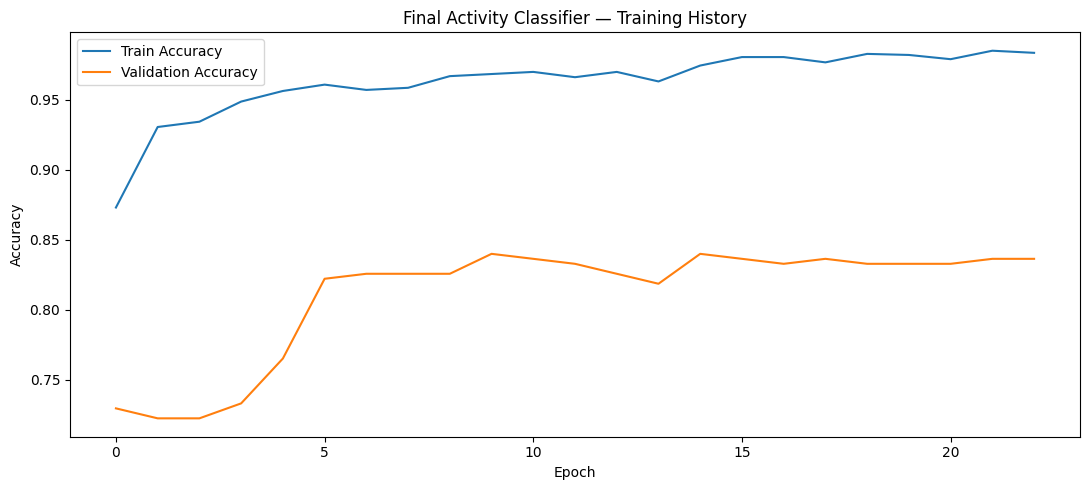

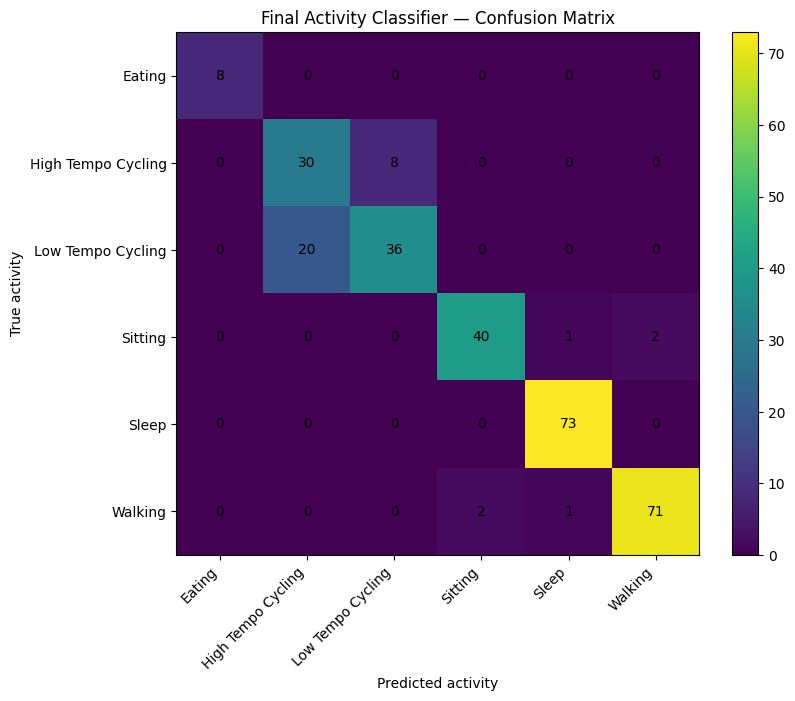

Saved activity figures.


In [29]:
activity_history_df = pd.DataFrame(
    activity_history.history
)

plt.figure(figsize=(11, 5))
plt.plot(
    activity_history_df["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    activity_history_df["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Final Activity Classifier — Training History")
plt.legend()
plt.tight_layout()

activity_history_path = FIGURES_DIR / "activity_training_history.png"
plt.savefig(
    activity_history_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()


cm = classification_confusion_matrix(
    y_activity_test,
    y_activity_pred,
    num_classes=len(ACTIVITY_ORDER),
    normalize=False,
)

plt.figure(figsize=(8.5, 7))
plt.imshow(cm)
plt.colorbar()

plt.xticks(
    np.arange(len(ACTIVITY_ORDER)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(ACTIVITY_ORDER)),
    class_names
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("Final Activity Classifier — Confusion Matrix")
plt.tight_layout()

activity_cm_path = FIGURES_DIR / "activity_confusion_matrix.png"
plt.savefig(
    activity_cm_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved activity figures.")

## 22. Save Final Project Summary

In [30]:
summary_rows = [
    {
        "Task": "Heart-rate regression",
        "Final_Model": "CNN + BiGRU PPG + IMU",
        "Primary_Metric": "MAE_BPM",
        "Primary_Value": hr_overall["MAE_BPM"],
        "Secondary_Metric": "R2",
        "Secondary_Value": hr_overall["R2"],
    },
    {
        "Task": "Activity classification",
        "Final_Model": "IMU 1D CNN",
        "Primary_Metric": "Accuracy",
        "Primary_Value": activity_overall["Accuracy"],
        "Secondary_Metric": "Macro_F1",
        "Secondary_Value": activity_overall["Macro_F1"],
    },
]

final_summary_df = pd.DataFrame(
    summary_rows
)

final_summary_path = METRICS_DIR / "final_summary.csv"

final_summary_df.to_csv(
    final_summary_path,
    index=False,
)

display(
    final_summary_df.round(4)
)

print("Saved:", final_summary_path)

,Task,Final_Model,Primary_Metric,Primary_Value,Secondary_Metric,Secondary_Value
0,Heart-rate regression,CNN + BiGRU PPG + IMU,MAE_BPM,3.8647,R2,0.9304
1,Activity classification,IMU 1D CNN,Accuracy,0.8836,Macro_F1,0.8826


Saved: C:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\final_summary.csv


## 23. Export Verification

In [31]:
expected_files = [
    MODELS_DIR / "hr_cnn_bigru.keras",
    MODELS_DIR / "hr_normalization.npz",
    MODELS_DIR / "activity_cnn.keras",
    MODELS_DIR / "activity_normalization.npz",
    MODELS_DIR / "activity_labels.json",
    METRICS_DIR / "hr_metrics.csv",
    METRICS_DIR / "hr_per_activity_metrics.csv",
    METRICS_DIR / "activity_metrics.csv",
    METRICS_DIR / "activity_classification_report.csv",
    METRICS_DIR / "final_summary.csv",
    FIGURES_DIR / "hr_training_history.png",
    FIGURES_DIR / "hr_test_predictions.png",
    FIGURES_DIR / "hr_predicted_vs_true.png",
    FIGURES_DIR / "activity_training_history.png",
    FIGURES_DIR / "activity_confusion_matrix.png",
]

verification = pd.DataFrame({
    "File": [
        str(path.relative_to(PROJECT_ROOT))
        for path in expected_files
    ],
    "Exists": [
        path.exists()
        for path in expected_files
    ],
})

display(verification)

if verification["Exists"].all():
    print("All final project artifacts were exported successfully.")
else:
    print("Some expected files are missing. Check the table above.")

,File,Exists
0,results\models\hr_cnn_bigru.keras,True
1,results\models\hr_normalization.npz,True
2,results\models\activity_cnn.keras,True
3,results\models\activity_normalization.npz,True
4,results\models\activity_labels.json,True
5,results\metrics\hr_metrics.csv,True
6,results\metrics\hr_per_activity_metrics.csv,True
7,results\metrics\activity_metrics.csv,True
8,results\metrics\activity_classification_report...,True
9,results\metrics\final_summary.csv,True


All final project artifacts were exported successfully.


## Final Output Structure

After a successful run, the project contains:

```text
results/
├── models/
│   ├── hr_cnn_bigru.keras
│   ├── hr_normalization.npz
│   ├── activity_cnn.keras
│   ├── activity_normalization.npz
│   └── activity_labels.json
│
├── metrics/
│   ├── hr_metrics.csv
│   ├── hr_per_activity_metrics.csv
│   ├── activity_metrics.csv
│   ├── activity_classification_report.csv
│   └── final_summary.csv
│
└── figures/
    ├── hr_training_history.png
    ├── hr_test_predictions.png
    ├── hr_predicted_vs_true.png
    ├── activity_training_history.png
    └── activity_confusion_matrix.png
```

These files represent the final exported project artifacts.